In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import stan
from pathlib import Path
from scipy.special import expit
from scipy.stats import norm, rankdata

import nest_asyncio
nest_asyncio.apply()

import logging
logging.getLogger().setLevel(logging.ERROR)

In [21]:
## Output folder for figures (as in model_pcf)
out_dir = Path("output")
out_dir.mkdir(parents=True, exist_ok=True)

### Data inspection and preprocessing

We test two complementary mechanisms of temporal pattern formation: **selective retention** (are more regularly spaced old territorial locations more likely to persist?) and **spatial anchoring** (do newly established locations improve spacing around retained locations more than randomly positioned additions?).

Inputs are exported by `compute_reuse_regularity.R`. Observations refer to **territorial locations**, not known male identities. Reuse is assessed across successive observations within the previous observation's KDE core. Negative changes in either irregularity measure mean *more regular* local spacing. Marking size is not included in these models.

In [22]:
## Load local measurements and persistence outcomes
local = pd.read_csv('processed_data/reuse_local_regularity.csv', parse_dates=['date'])
retention = pd.read_csv('processed_data/reuse_retention_pointwise.csv', parse_dates=['date_prev', 'date_curr'])
data = pd.read_csv('processed_data/reuse_transition_summary.csv', parse_dates=['date_prev', 'date_curr'])

## Load observed addition effects and the matched spatial randomisations
addition = pd.read_csv('processed_data/reuse_addition_pointwise.csv', parse_dates=['date_prev', 'date_curr'])
observed = pd.read_csv('processed_data/reuse_addition_summary.csv', parse_dates=['date_prev', 'date_curr'])
randomisations = pd.read_csv('processed_data/reuse_addition_null.csv', parse_dates=['date_prev', 'date_curr'])

retention.head()

,X,longitude,latitude,lek_id,date,point_id,nnd,nnd_reference,nnd_irregularity,six_neighbour_cv,six_neighbour_radius,boundary_distance,nnd_edge_ok,six_neighbour_edge_ok,date_prev,date_curr,interval_days,nnd_to_next,persistent,persistence_edge_ok
0,0,74.436865,27.800003,Tal Chhapar,2012-10-01,0,13.671106,15.880343,0.149797,0.188504,22.321949,176.886782,True,True,2012-10-01,2014-02-01,488,1.947405,True,True
1,1,74.437586,27.800908,Tal Chhapar,2012-10-01,1,18.543304,15.880343,0.155027,0.275553,45.071186,56.354201,True,True,2012-10-01,2014-02-01,488,4.863054,True,True
2,2,74.437337,27.801097,Tal Chhapar,2012-10-01,2,14.414329,15.880343,0.096859,0.293247,35.461006,59.827063,True,True,2012-10-01,2014-02-01,488,13.307303,False,True
3,3,74.437137,27.800904,Tal Chhapar,2012-10-01,3,11.903594,15.880343,0.288242,0.257615,29.066565,88.820679,True,True,2012-10-01,2014-02-01,488,6.993262,False,True
4,4,74.437433,27.800634,Tal Chhapar,2012-10-01,4,21.271299,15.880343,0.292277,0.197662,37.702375,88.202085,True,True,2012-10-01,2014-02-01,488,2.047064,True,True


In [23]:
## Factor ordering + labels (same site order as model_pcf)
lek_labels = ['Tal Chhapar', 'Velavadar Lek 1', 'Velavadar Lek 2']

for df in [local, retention, data, addition, observed, randomisations]:
    df['lek_id'] = pd.Categorical(df['lek_id'], categories=lek_labels, ordered=True)
    if df['lek_id'].isna().any():
        raise ValueError('Unrecognised lek_id in one of the input CSVs. Check site labels.')

## Use Stan's 1-based indexing, as in the PCF notebook
site_lookup = {lek: i + 1 for i, lek in enumerate(lek_labels)}
site_to_lek = {i + 1: lek for i, lek in enumerate(lek_labels)}
for df in [local, retention, data, addition, observed, randomisations]:
    df['site_id'] = df['lek_id'].map(site_lookup).astype(int)

lek_labels_ordered = lek_labels.copy()

In [24]:
## Colour palettes (identical to model_pcf)
fill_cols = {'Tal Chhapar': '#B5542D', 'Velavadar Lek 1': '#1F6F8B', 'Velavadar Lek 2': '#3FA7A3'}
point_cols = {'Tal Chhapar': '#D97A52', 'Velavadar Lek 1': '#15556B', 'Velavadar Lek 2': '#2B7E7B'}

## One date represents an observation month, not an exact behavioural sampling time
comparison_keys = ['lek_id', 'date_prev', 'date_curr']
metrics = [('six_neighbour_cv', 'six_neighbour_edge_ok', 'Six-neighbour distance CV')]
metric_short = {'six_neighbour_cv': 'six_cv'}

### Eligible focal locations across transitions

These plots describe the available sample for the spatial anchoring comparison. Six-neighbour eligibility requires the neighbourhood to remain inside the lek polygon. Six-neighbour CV uses all six neighbour distances, with the sixth providing its boundary radius. A transition without reused locations has no addition estimate and is shown with zero eligible locations.

In [25]:
## Match comparison coverage to every observed transition
coverage = data.merge(observed[['lek_id', 'date_prev', 'date_curr', 'n_six_eligible']],
                      on=comparison_keys, how='left')
coverage[['n_six_eligible']] = (
    coverage[['n_six_eligible']].fillna(0).astype(int)
)
coverage[['lek_id', 'date_prev', 'date_curr', 'n_reused', 'n_six_eligible', 'n_null_complete']]

,lek_id,date_prev,date_curr,n_reused,n_six_eligible,n_null_complete
0,Tal Chhapar,2012-10-01,2014-02-01,116,112,1000
1,Tal Chhapar,2014-02-01,2015-11-01,79,79,1000
2,Tal Chhapar,2015-11-01,2015-12-01,91,89,1000
3,Tal Chhapar,2015-12-01,2018-01-01,66,65,1000
4,Tal Chhapar,2018-01-01,2018-11-01,87,86,1000
5,Tal Chhapar,2018-11-01,2019-10-01,81,81,1000
6,Tal Chhapar,2019-10-01,2021-02-01,97,96,1000
7,Tal Chhapar,2021-02-01,2022-03-01,96,96,1000
8,Tal Chhapar,2022-03-01,2023-12-01,116,116,1000
9,Velavadar Lek 1,2013-12-01,2014-02-01,35,35,1000


### Selective retention: empirical spacing distributions

We compare local irregularity in the *previous* observation between territorial locations that do and do not persist into the next observation. The sample is restricted to previous-core locations with adequate polygon-edge clearance. The sample also requires adequate edge clearance for the six-neighbour CV measurement.

In [26]:
## Define the eligible persistence sample
persistence_sample = retention.loc[retention['persistence_edge_ok'].fillna(False)].copy()

### Model the **transition-adjusted effect** of local irregularity on territorial retention

We fit a Bernoulli-logit model for six-neighbour CV, preserving the original reuse model's `normal(0, 1)` priors and PCF-style PyStan sampling (`4` chains, `1,000` warmup, `1,000` retained iterations). Each lek × observation transition gets its own intercept; each lek gets an irregularity slope.

For comparability across transitions, irregularity is centred within its transition and scaled by the full eligible sample's standard deviation. **Negative** `beta` means stronger retention of comparatively regular locations, with an odds ratio `exp(beta) < 1` per one SD increase in irregularity. Transition baselines absorb observation-pair differences; this is not a model of continuous change through time. Location-level outcomes are treated as conditionally independent, and residual spatial dependence or density effects are not resolved here.

In [27]:
## Prepare samples and construct PCF-style 1-based categorical IDs
retention_tables = {}

for metric, edge_flag, label in metrics:
    sample = persistence_sample.loc[persistence_sample[edge_flag].fillna(False) &
                                    np.isfinite(persistence_sample[metric])].copy().reset_index(drop=True)
    sample = sample.loc[sample['persistent'].notna()].copy().reset_index(drop=True)
    sample['transition_id'] = sample.groupby(comparison_keys, observed=True).ngroup() + 1
    if sample['transition_id'].isna().any() or len(sample) == 0:
        raise ValueError(f'No valid transitions for {metric}')

    # Standardise around each transition's contemporaneous average
    centred = sample[metric] - sample.groupby('transition_id')[metric].transform('mean')
    scale = sample[metric].std()
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError(f'Cannot standardise {metric}: standard deviation is not positive')
    sample['irregularity_z'] = centred / scale
    retention_tables[metric] = sample

pd.concat([pd.DataFrame({'measure': label,
                         'n_locations': [len(retention_tables[metric])],
                         'n_transitions': [retention_tables[metric]['transition_id'].nunique()]})
           for metric, edge_flag, label in metrics], ignore_index=True)

,measure,n_locations,n_transitions
0,Six-neighbour distance CV,2731,31


In [28]:
## Bernoulli-logit model: transition intercepts and site-specific local irregularity effects
## Site and transition indices are 1-based, matching model_pcf
reuse_mod = """
data {
    int<lower=1> n_points;
    int<lower=1> n_transitions;
    int<lower=1> n_sites;
    array[n_points] int<lower=0, upper=1> reuse;
    array[n_points] int<lower=1, upper=n_transitions> transition_id;
    array[n_points] int<lower=1, upper=n_sites> site_id;
    vector[n_points] irregularity;
}

parameters {
    vector[n_transitions] alpha;
    vector[n_sites] beta;
}

model {
    alpha ~ normal(0, 1);
    beta ~ normal(0, 1);
    reuse ~ bernoulli_logit(alpha[transition_id] + beta[site_id] .* irregularity);
}

generated quantities {
    // Replicated numbers of retained territories per transition (compact PPC output)
    array[n_transitions] int<lower=0> reuse_rep = rep_array(0, n_transitions);

    for (n in 1:n_points) {
        reuse_rep[transition_id[n]] += bernoulli_logit_rng(
            alpha[transition_id[n]] + beta[site_id[n]] * irregularity[n]);
    }
}
"""

In [29]:
sample = retention_tables['six_neighbour_cv']
reuse_data = {
    'n_points': len(sample),
    'n_transitions': int(sample['transition_id'].nunique()),
    'n_sites': len(lek_labels_ordered),
    'reuse': sample['persistent'].astype(int).to_numpy(),
    'transition_id': sample['transition_id'].astype(int).to_numpy(),
    'site_id': sample['site_id'].astype(int).to_numpy(),
    'irregularity': sample['irregularity_z'].astype(float).to_numpy()
}

posterior = stan.build(reuse_mod, data=reuse_data, random_seed=123)
fit = posterior.sample(num_chains=4, num_warmup=1000, num_samples=1000)

retention_fits = {'six_neighbour_cv': fit}

Building...



Building: found in cache, done.Sampling:   0%
Sampling: 100%, done.
Messages received during sampling:
  Gradient evaluation took 0.000106 seconds
  1000 transitions using 10 leapfrog steps per transition would take 1.06 seconds.
  Adjust your expectations accordingly!
  Gradient evaluation took 0.000108 seconds
  1000 transitions using 10 leapfrog steps per transition would take 1.08 seconds.
  Adjust your expectations accordingly!
  Gradient evaluation took 0.00011 seconds
  1000 transitions using 10 leapfrog steps per transition would take 1.1 seconds.
  Adjust your expectations accordingly!
  Gradient evaluation took 0.000121 seconds
  1000 transitions using 10 leapfrog steps per transition would take 1.21 seconds.
  Adjust your expectations accordingly!


### Posterior effects and between-lek comparisons

As in the PCF notebook, we calculate posterior medians, central 95% intervals, directional probabilities, and exponentiated log-odds effects directly from `fit['beta']`. Site differences here compare **slopes** (responses to irregularity), not baseline territorial reuse rates. Smaller slopes imply stronger preferential retention of regular locations.

In [30]:
## Report site-specific posterior effects: log odds and odds ratios per SD irregularity
retention_effect_rows = []
pairwise_effect_rows = []

for metric, edge_flag, label in metrics:
    fit = retention_fits[metric]
    beta = fit['beta']                      # (3 sites, n_draws)
    for site_id, lek in enumerate(lek_labels_ordered):
        draws = beta[site_id, :]
        lower, median, upper = np.quantile(draws, [0.025, 0.5, 0.975])
        retention_effect_rows.append({
            'measure': label, 'lek_id': lek,
            'beta_median': median, 'beta_lower': lower, 'beta_upper': upper,
            'odds_ratio': np.exp(median), 'odds_ratio_lower': np.exp(lower),
            'odds_ratio_upper': np.exp(upper), 'Pr(beta < 0)': np.mean(draws < 0)
        })

    # Direct analogue of the PCF notebook's between-site posterior contrasts
    for i, j in [(0, 1), (0, 2), (1, 2)]:
        delta = beta[i] - beta[j]
        q = np.quantile(delta, [0.025, 0.5, 0.975])
        pairwise_effect_rows.append({
            'measure': label, 'contrast': f'{lek_labels_ordered[i]} − {lek_labels_ordered[j]}',
            'beta_difference_median': q[1], 'lower': q[0], 'upper': q[2],
            'odds_ratio_of_effects': np.exp(q[1]),
            'Pr(first slope < second)': (delta < 0).mean()
        })

retention_effects = pd.DataFrame(retention_effect_rows)
retention_effects

,measure,lek_id,beta_median,beta_lower,beta_upper,odds_ratio,odds_ratio_lower,odds_ratio_upper,Pr(beta < 0)
0,Six-neighbour distance CV,Tal Chhapar,-0.609931,-0.776506,-0.444260,0.543388,0.460010,0.641298,1.0000
1,Six-neighbour distance CV,Velavadar Lek 1,-0.098906,-0.265997,0.063685,0.905827,0.766442,1.065757,0.8795
2,Six-neighbour distance CV,Velavadar Lek 2,-0.368408,-0.532751,-0.213384,0.691835,0.586988,0.807846,1.0000


In [31]:
## Probabilities of more negative (stronger selective-retention) slopes across leks
pairwise_effects = pd.DataFrame(pairwise_effect_rows)
pairwise_effects

,measure,contrast,beta_difference_median,lower,upper,odds_ratio_of_effects,Pr(first slope < second)
0,Six-neighbour distance CV,Tal Chhapar − Velavadar Lek 1,-0.511443,-0.739841,-0.283534,0.599630,1.00000
1,Six-neighbour distance CV,Tal Chhapar − Velavadar Lek 2,-0.240588,-0.466470,-0.003098,0.786165,0.97625
2,Six-neighbour distance CV,Velavadar Lek 1 − Velavadar Lek 2,0.269226,0.035408,0.505232,1.308951,0.01025


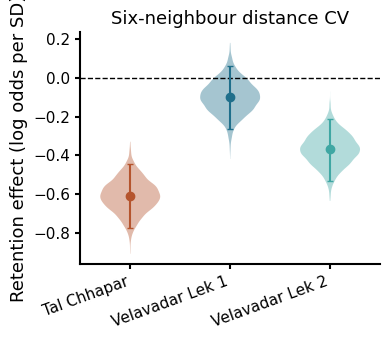

In [32]:
## Posterior slope violins with medians + 95% intervals (PCF colour/styling)
fig, ax = plt.subplots(figsize=(4, 3.5))
x_pos = np.arange(len(lek_labels_ordered))

beta = retention_fits['six_neighbour_cv']['beta']
for site_id, lek in enumerate(lek_labels_ordered):
    samples = beta[site_id, :]
    parts = ax.violinplot(samples, positions=[x_pos[site_id]], widths=0.6,
                          showmeans=False, showmedians=False, showextrema=False)
    for pc in parts['bodies']:
        pc.set_facecolor(fill_cols[lek])
        pc.set_edgecolor('none')
        pc.set_alpha(0.4)
    median = np.median(samples)
    lower, upper = np.quantile(samples, [0.025, 0.975])
    ax.errorbar(x_pos[site_id], median,
                yerr=[[median - lower], [upper - median]],
                fmt='o', color=fill_cols[lek], markersize=6, capsize=2, zorder=3)

ax.axhline(0, color='black', linewidth=1, linestyle='--')
ax.set_xlim(-0.5, len(lek_labels_ordered) - 0.5)
ax.set_title('Six-neighbour distance CV', fontsize=13)
ax.set_xticks(x_pos)
ax.set_xticklabels(lek_labels_ordered, rotation=20, ha='right', fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)
ax.tick_params(axis='both', which='major', labelsize=11, width=1.5)

ax.set_ylabel('Retention effect (log odds per SD)', fontsize=13)
plt.tight_layout()
plt.show()

### Empirical vs modelled persistence probability (PCF posterior-probability analogue)

The PCF notebook plots categorical probabilities for numbers of peaks. Here the binary categories are **not retained (0)** and **retained (1)**. For each site, we average the model's predicted retention probability across its actual eligible locations and transition intercepts. This keeps the empirical and posterior summaries on the same sample and avoids treating an arbitrary intercept as a site mean. Bars are central 95% posterior intervals.

In [33]:
## Site-specific model-implied probabilities and compact posterior-predictive rates
## Work by transition to avoid allocating a huge (n_locations × n_draws) matrix
posterior_categories = {}
predictive_categories = {}
empirical_categories = {}
site_ppc_checks = []

for metric, edge_flag, label in metrics:
    sample = retention_tables[metric]
    fit = retention_fits[metric]
    alpha = fit['alpha']                 # (n_transitions, n_draws)
    beta = fit['beta']                   # (3, n_draws)
    replicated_counts = fit['reuse_rep']  # (n_transitions, n_draws)
    n_draws = beta.shape[1]

    model_rows, ppc_rows, obs_rows = [], [], []
    for site_id, lek in enumerate(lek_labels_ordered, start=1):
        sub = sample.loc[sample['site_id'] == site_id]
        if sub.empty:
            raise ValueError(f'No observations for {lek} in {metric}')
        expected = np.zeros(n_draws)
        transition_ids = []
        for transition_id, trans in sub.groupby('transition_id'):
            transition_ids.append(int(transition_id))
            z = trans['irregularity_z'].to_numpy()
            # Small chunks keep memory bounded even for large territory datasets
            for start in range(0, len(z), 250):
                chunk = z[start:start + 250]
                expected += expit(alpha[int(transition_id) - 1, None, :] +
                                  chunk[:, None] * beta[site_id - 1, None, :]).sum(axis=0)

        p_model = expected / len(sub)
        p_rep = replicated_counts[np.array(transition_ids) - 1, :].sum(axis=0) / len(sub)
        p_obs = sub['persistent'].mean()

        for category in [0, 1]:
            observed_prob = (1 - p_obs) if category == 0 else p_obs
            pred_model = (1 - p_model) if category == 0 else p_model
            pred_rep = (1 - p_rep) if category == 0 else p_rep
            lo, med, hi = np.quantile(pred_model, [0.025, 0.5, 0.975])
            rlo, rmed, rhi = np.quantile(pred_rep, [0.025, 0.5, 0.975])
            obs_rows.append({'lek_id': lek, 'retained': category, 'prop': observed_prob})
            model_rows.append({'lek_id': lek, 'retained': category,
                               'median': med, 'lower': lo, 'upper': hi})
            ppc_rows.append({'lek_id': lek, 'retained': category,
                             'median': rmed, 'lower': rlo, 'upper': rhi})

        plo, phi = np.quantile(p_rep, [0.025, 0.975])
        site_ppc_checks.append({
            'measure': label, 'lek_id': lek, 'n': len(sub), 'observed_rate': p_obs,
            'PPC_median': np.median(p_rep), 'PPC_lower': plo, 'PPC_upper': phi,
            'observed_outside_PPC_95': bool(p_obs < plo or p_obs > phi)
        })

    posterior_categories[metric] = pd.DataFrame(model_rows)
    predictive_categories[metric] = pd.DataFrame(ppc_rows)
    empirical_categories[metric] = pd.DataFrame(obs_rows)

site_ppc_summary = pd.DataFrame(site_ppc_checks)
site_ppc_summary

,measure,lek_id,n,observed_rate,PPC_median,PPC_lower,PPC_upper,observed_outside_PPC_95
0,Six-neighbour distance CV,Tal Chhapar,1383,0.595083,0.591468,0.558207,0.624729,False
1,Six-neighbour distance CV,Velavadar Lek 1,674,0.456973,0.459941,0.412463,0.507418,False
2,Six-neighbour distance CV,Velavadar Lek 2,674,0.412463,0.418398,0.372366,0.465875,False


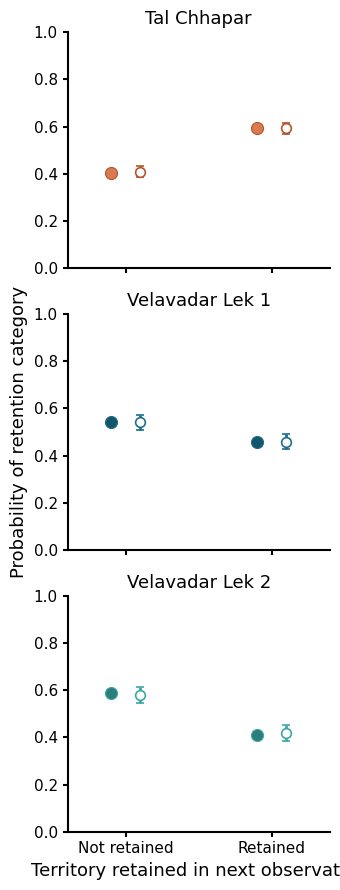

In [34]:
## Plot empirical probabilities vs modelled categorical posterior probabilities
for metric, edge_flag, label in metrics:
    fig, axes = plt.subplots(3, 1, figsize=(3.5, 9), sharex=True)
    for ax, lek in zip(axes, lek_labels_ordered):
        empirical = empirical_categories[metric].loc[lambda d: d['lek_id'] == lek]
        post = posterior_categories[metric].loc[lambda d: d['lek_id'] == lek]
        ax.scatter(empirical['retained'] - 0.10, empirical['prop'], s=75,
                   facecolor=point_cols[lek], edgecolor=fill_cols[lek], linewidth=0.8,
                   zorder=4, label='Empirical')
        ax.errorbar(post['retained'] + 0.10, post['median'],
                    yerr=[post['median'] - post['lower'], post['upper'] - post['median']],
                    fmt='o', markersize=7, mfc='white', mec=fill_cols[lek], mew=1.2,
                    color=fill_cols[lek], elinewidth=2, capsize=3, zorder=3,
                    label='Posterior median ± 95% CI')
        ax.set_xticks([0, 1], ['Not retained', 'Retained'])
        ax.set_xlim(-0.4, 1.4)
        ax.set_ylim(0, 1)
        ax.set_title(lek, fontsize=13)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        ax.tick_params(axis='both', which='major', labelsize=11, width=1.5)

    axes[1].set_ylabel('Probability of retention category', fontsize=13)
    axes[-1].set_xlabel('Territory retained in next observation', fontsize=13)
    plt.tight_layout()
    # plt.savefig(out_dir/f'mod_reuse_categories_{metric_short[metric]}.png', dpi=300, bbox_inches='tight')

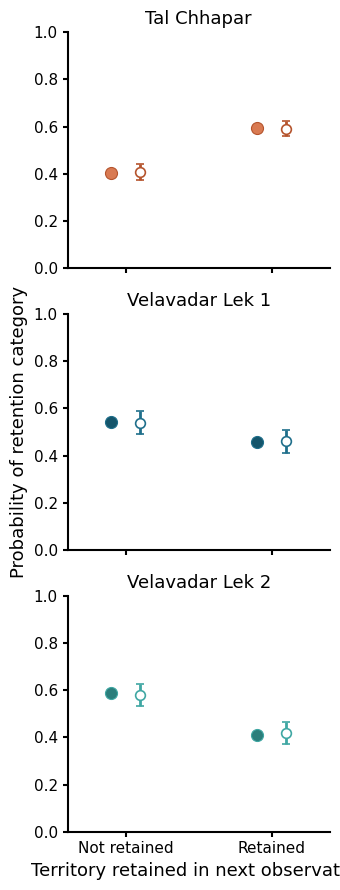

In [35]:
## Posterior predictive check: observed vs replicated category probabilities
for metric, edge_flag, label in metrics:
    fig, axes = plt.subplots(3, 1, figsize=(3.5, 9), sharex=True)
    for ax, lek in zip(axes, lek_labels_ordered):
        empirical = empirical_categories[metric].loc[lambda d: d['lek_id'] == lek]
        ppc = predictive_categories[metric].loc[lambda d: d['lek_id'] == lek]
        ax.scatter(empirical['retained'] - 0.10, empirical['prop'], s=75,
                   facecolor=point_cols[lek], edgecolor=fill_cols[lek], linewidth=0.8,
                   zorder=4, label='Empirical')
        ax.errorbar(ppc['retained'] + 0.10, ppc['median'],
                    yerr=[ppc['median'] - ppc['lower'], ppc['upper'] - ppc['median']],
                    fmt='o', markersize=7, mfc='white', mec=fill_cols[lek], mew=1.2,
                    color=fill_cols[lek], elinewidth=2, capsize=3, zorder=3,
                    label='PPC median ± 95% CI')
        ax.set_xticks([0, 1], ['Not retained', 'Retained'])
        ax.set_xlim(-0.4, 1.4)
        ax.set_ylim(0, 1)
        ax.set_title(lek, fontsize=13)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        ax.tick_params(axis='both', which='major', labelsize=11, width=1.5)

    axes[1].set_ylabel('Probability of retention category', fontsize=13)
    axes[-1].set_xlabel('Territory retained in next observation', fontsize=13)
    plt.tight_layout()
    # plt.savefig(out_dir/f'mod_post_reuse_categories_{metric_short[metric]}.png', dpi=300, bbox_inches='tight')

### Predicted effect of irregularity within leks

These are marginal Bernoulli-logit response curves, analogous to the PCF model's posterior predictions through time. Here the horizontal axis is *local irregularity* (in SD units): each site's curve averages its fitted transition intercepts, weighted by the number of eligible territorial locations in each transition. Curves show posterior medians and central 95% intervals, **not** a causal effect or a time trend.

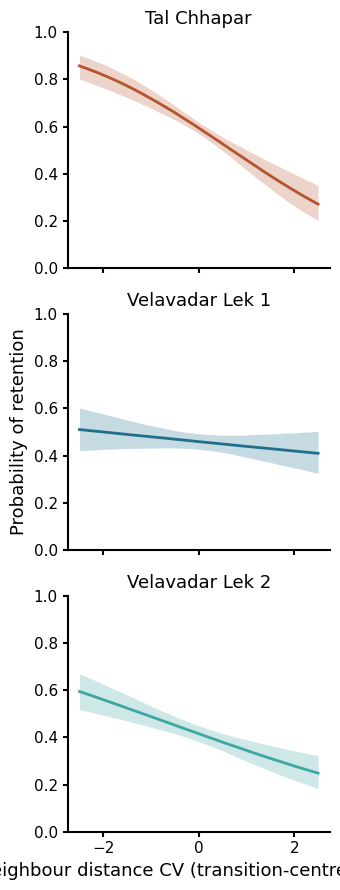

In [36]:
## Prediction grid, analogous to t_grid in model_pcf
irregularity_grid = np.linspace(-2.5, 2.5, 150)

for metric, edge_flag, label in metrics:
    fit = retention_fits[metric]
    sample = retention_tables[metric]
    alpha, beta = fit['alpha'], fit['beta']
    fig, axes = plt.subplots(3, 1, figsize=(3.5, 9), sharex=True, sharey=True)

    for site_id, (ax, lek) in enumerate(zip(axes, lek_labels_ordered), start=1):
        sub = sample.loc[sample['site_id'] == site_id]
        transition_sizes = sub.groupby('transition_id').size()
        p_grid = np.zeros((beta.shape[1], len(irregularity_grid)))
        for transition_id, size in transition_sizes.items():
            eta = alpha[int(transition_id) - 1, :, None] + (beta[site_id - 1, :, None] *
                                                             irregularity_grid[None, :])
            p_grid += (size / len(sub)) * expit(eta)

        median = np.median(p_grid, axis=0)
        lower, upper = np.quantile(p_grid, [0.025, 0.975], axis=0)
        ax.plot(irregularity_grid, median, color=fill_cols[lek], lw=2)
        ax.fill_between(irregularity_grid, lower, upper, color=fill_cols[lek], alpha=0.25, lw=0)
        ax.set_title(lek, fontsize=13)
        ax.set_ylim(0, 1)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        ax.tick_params(axis='both', which='major', labelsize=11, width=1.5)

    axes[1].set_ylabel('Probability of retention', fontsize=13)
    axes[-1].set_xlabel(f'{label} (transition-centred, SD units)', fontsize=13)
    plt.tight_layout()
    # plt.savefig(out_dir/f'mod_reuse_irregularity_curve_{metric_short[metric]}.png', dpi=300, bbox_inches='tight')

In [37]:
## Expected and replicated transition rates, plus a transition-level PPC summary
transition_predictions = {}
transition_ppc_rows = []

for metric, edge_flag, label in metrics:
    fit = retention_fits[metric]
    sample = retention_tables[metric]
    alpha, beta, reuse_rep = fit['alpha'], fit['beta'], fit['reuse_rep']
    rows = []

    for transition_id, sub in sample.groupby('transition_id'):
        t = int(transition_id) - 1
        site_id = int(sub['site_id'].iloc[0])
        z = sub['irregularity_z'].to_numpy()
        expected = np.zeros(beta.shape[1])
        for start in range(0, len(z), 250):
            chunk = z[start:start + 250]
            expected += expit(alpha[t, None, :] +
                              chunk[:, None] * beta[site_id - 1, None, :]).sum(axis=0)
        p_model = expected / len(sub)
        p_rep = reuse_rep[t, :] / len(sub)
        obs_rate = sub['persistent'].mean()
        mlo, mmed, mhi = np.quantile(p_model, [0.025, 0.5, 0.975])
        rlo, rmed, rhi = np.quantile(p_rep, [0.025, 0.5, 0.975])
        rows.append({
            'lek_id': sub['lek_id'].iloc[0], 'date_prev': sub['date_prev'].iloc[0],
            'date_curr': sub['date_curr'].iloc[0], 'transition_id': transition_id,
            'n': len(sub), 'observed_rate': obs_rate,
            'model_lower': mlo, 'model_median': mmed, 'model_upper': mhi,
            'ppc_lower': rlo, 'ppc_median': rmed, 'ppc_upper': rhi
        })
        transition_ppc_rows.append({
            'measure': label, 'lek_id': sub['lek_id'].iloc[0],
            'date_curr': sub['date_curr'].iloc[0],
            'outside_PPC_95': bool(obs_rate < rlo or obs_rate > rhi),
            'absolute_rate_error': abs(obs_rate - np.mean(p_rep))
        })
    transition_predictions[metric] = pd.DataFrame(rows)

transition_ppc_checks = (pd.DataFrame(transition_ppc_rows)
                         .groupby('measure', as_index=False)
                         .agg(n_transitions=('outside_PPC_95', 'size'),
                              outside_predictive_interval=('outside_PPC_95', 'sum'),
                              mean_absolute_rate_error=('absolute_rate_error', 'mean')))
transition_ppc_checks

,measure,n_transitions,outside_predictive_interval,mean_absolute_rate_error
0,Six-neighbour distance CV,31,0,0.019317


In [38]:
## PCF-style summary: posterior retention probabilities at first and last sampled transitions
for metric, edge_flag, label in metrics:
    print(f'\n{label}')
    fit = retention_fits[metric]
    sample = retention_tables[metric]
    for lek in lek_labels_ordered:
        sub = sample.loc[sample['lek_id'] == lek]
        transitions = sub.groupby('transition_id')['date_curr'].first().sort_values()
        first_id, last_id = int(transitions.index[0]), int(transitions.index[-1])
        for name, t_id in [('First', first_id), ('Last', last_id)]:
            trans = sub.loc[sub['transition_id'] == t_id]
            z = trans['irregularity_z'].to_numpy()
            # Prediction averages over observed irregularities within this transition
            p = np.zeros(fit['beta'].shape[1])
            for start in range(0, len(z), 250):
                chunk = z[start:start+250]
                p += expit(fit['alpha'][t_id - 1, None, :] +
                           chunk[:, None] * fit['beta'][site_lookup[lek] - 1, None, :]).sum(axis=0)
            q = np.quantile(p / len(z), [0.025, 0.5, 0.975])
            date = trans['date_curr'].iloc[0].strftime('%Y-%m')
            print(f'  {lek}: {name.lower()} transition ({date}): '
                  f'median P(retained) = {q[1]:.3f}, 95% CI [{q[0]:.3f}, {q[2]:.3f}]')


Six-neighbour distance CV
  Tal Chhapar: first transition (2014-02): median P(retained) = 0.697, 95% CI [0.624, 0.762]
  Tal Chhapar: last transition (2023-12): median P(retained) = 0.858, 95% CI [0.796, 0.908]
  Velavadar Lek 1: first transition (2014-02): median P(retained) = 0.809, 95% CI [0.669, 0.904]
  Velavadar Lek 1: last transition (2024-05): median P(retained) = 0.142, 95% CI [0.040, 0.340]
  Velavadar Lek 2: first transition (2015-05): median P(retained) = 0.520, 95% CI [0.333, 0.701]
  Velavadar Lek 2: last transition (2024-05): median P(retained) = 0.644, 95% CI [0.556, 0.727]
